In [1]:
import torch
from src.models.model import GalaxyClassifier_ResNet
from pytorch_grad_cam import GradCAM
from PIL import Image
import io
import base64
import numpy as np
import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from torchvision import transforms
import mlflow
from mlflow.tracking import MlflowClient
import random
 

d:\galaxy_classification-dev\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def build_gradcam(model: torch.nn.Module) -> GradCAM:
    target_layer = [model.group5.units[-1].conv2]
    return GradCAM(model=model, target_layers=target_layer)

In [3]:
def load_best_model(experiment_name: str) -> torch.nn.Module:
    client = MlflowClient()
    experiment = client.get_experiment_by_name(experiment_name)
    
    if experiment is None:
        raise ValueError(f"Experiment '{experiment_name}' not found")

    runs = client.search_runs(
        experiment_ids=[experiment.experiment_id],
        filter_string="attributes.status = 'FINISHED'",
        order_by=["metrics.val_f1_macro DESC"],
        max_results=1,
    )

    if not runs:
        raise ValueError(f"No finished runs in experiment '{experiment_name}'")

    best_run = runs[0]
    model_uri = f"runs:/{best_run.info.run_id}/model"
    return mlflow.pytorch.load_model(model_uri) #preload while return


In [7]:
mlflow.set_tracking_uri("http://localhost:5000")


In [8]:
model = load_best_model("galaxy-classification-default-experiments")

In [9]:
gradcam = build_gradcam(model)


In [14]:

def run_gradcam(
    cam: GradCAM,tensor: torch.Tensor,
    orig_img: Image.Image) -> str:
    

    """Return base64-encoded PNG heatmap overlay for a single image tensor."""

    grayscale_cam = cam(input_tensor=tensor.unsqueeze(0), targets=None)[0]
    img_rgb = np.array(orig_img.resize((128, 128))) / 255.0
    heatmap = show_cam_on_image(img_rgb.astype(np.float32), grayscale_cam, use_rgb=True)
    buf = io.BytesIO()
    Image.fromarray(heatmap).save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode()

In [16]:
raw_transforms = transforms.Compose([
    transforms.CenterCrop(random.randint(170, 240)),  
    transforms.Resize(160),                            
    transforms.RandomCrop(128),                        
    transforms.RandomRotation(degrees = [90, 180]),
    transforms.RandomRotation(degrees = [0,270]),      
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.1376, 0.1276, 0.1187],
                         std= [0.1728, 0.1586, 0.1488])    
])


In [ ]:
orig_img = Image.open(r"D:\galaxy classification\images\6.jpg").convert("RGB")



In [17]:

result = run_gradcam(gradcam, raw_transforms(orig_img), orig_img)


In [31]:
np.shape(raw_transforms(orig_img).unsqueeze(0))

torch.Size([1, 3, 128, 128])

In [23]:
import matplotlib.pyplot as plt
from io import BytesIO


### Sample gradcam visual

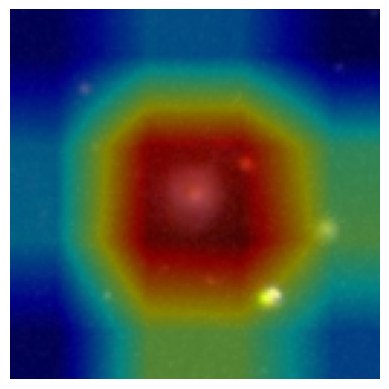

In [24]:
img_bytes = base64.b64decode(result)

img = Image.open(BytesIO(img_bytes))



plt.imshow(img)

plt.axis("off")

plt.show()